In [13]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns

In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])

trainset = torchvision.datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=64, shuffle=True)

testset = torchvision.datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=64, shuffle=False)

classes = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

In [7]:
class FashionMLP(nn.Module):
    def __init__(self):
        super(FashionMLP, self).__init__()
        self.flatten = nn.Flatten()
        self.network = nn.Sequential(
            nn.Linear(28*28, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.network(x)

model = FashionMLP().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [8]:
epochs = 15
train_losses, test_losses = [], []

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    train_losses.append(running_loss / len(trainloader))
    model.eval()
    test_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in testloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            test_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    test_losses.append(test_loss / len(testloader))
    acc = 100 * correct / total
    print(f"Epoka {epoch+1}/{epochs} | Train Loss: {train_losses[-1]:.4f} | Test Loss: {test_losses[-1]:.4f} | Test Accuracy: {acc:.2f}%")

Epoka 1/15 | Train Loss: 0.5016 | Test Loss: 0.4251 | Test Accuracy: 84.58%
Epoka 2/15 | Train Loss: 0.3717 | Test Loss: 0.3687 | Test Accuracy: 86.18%
Epoka 3/15 | Train Loss: 0.3309 | Test Loss: 0.3742 | Test Accuracy: 86.13%
Epoka 4/15 | Train Loss: 0.3075 | Test Loss: 0.3683 | Test Accuracy: 86.96%
Epoka 5/15 | Train Loss: 0.2866 | Test Loss: 0.3480 | Test Accuracy: 87.29%
Epoka 6/15 | Train Loss: 0.2695 | Test Loss: 0.3397 | Test Accuracy: 87.69%
Epoka 7/15 | Train Loss: 0.2524 | Test Loss: 0.3595 | Test Accuracy: 87.39%
Epoka 8/15 | Train Loss: 0.2406 | Test Loss: 0.3343 | Test Accuracy: 88.04%
Epoka 9/15 | Train Loss: 0.2280 | Test Loss: 0.3400 | Test Accuracy: 88.51%
Epoka 10/15 | Train Loss: 0.2156 | Test Loss: 0.3516 | Test Accuracy: 88.04%
Epoka 11/15 | Train Loss: 0.2055 | Test Loss: 0.3535 | Test Accuracy: 88.42%
Epoka 12/15 | Train Loss: 0.1964 | Test Loss: 0.3726 | Test Accuracy: 88.67%
Epoka 13/15 | Train Loss: 0.1876 | Test Loss: 0.3503 | Test Accuracy: 89.02%
Epoka 14

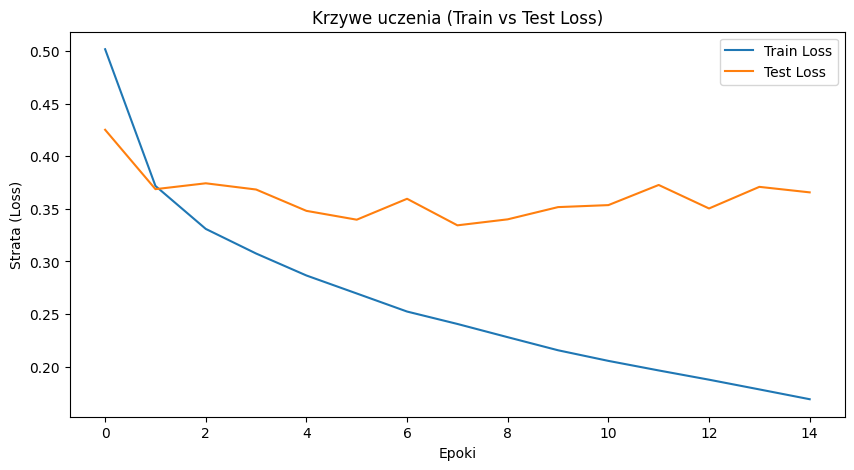

In [9]:
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Train Loss')
plt.plot(test_losses, label='Test Loss')
plt.title('Krzywe uczenia (Train vs Test Loss)')
plt.xlabel('Epoki')
plt.ylabel('Strata (Loss)')
plt.legend()
plt.show()

In [10]:
dataiter = iter(testloader)
images, labels = next(dataiter)
images, labels = images.to(device), labels.to(device)
outputs = model(images)
_, preds = torch.max(outputs, 1)

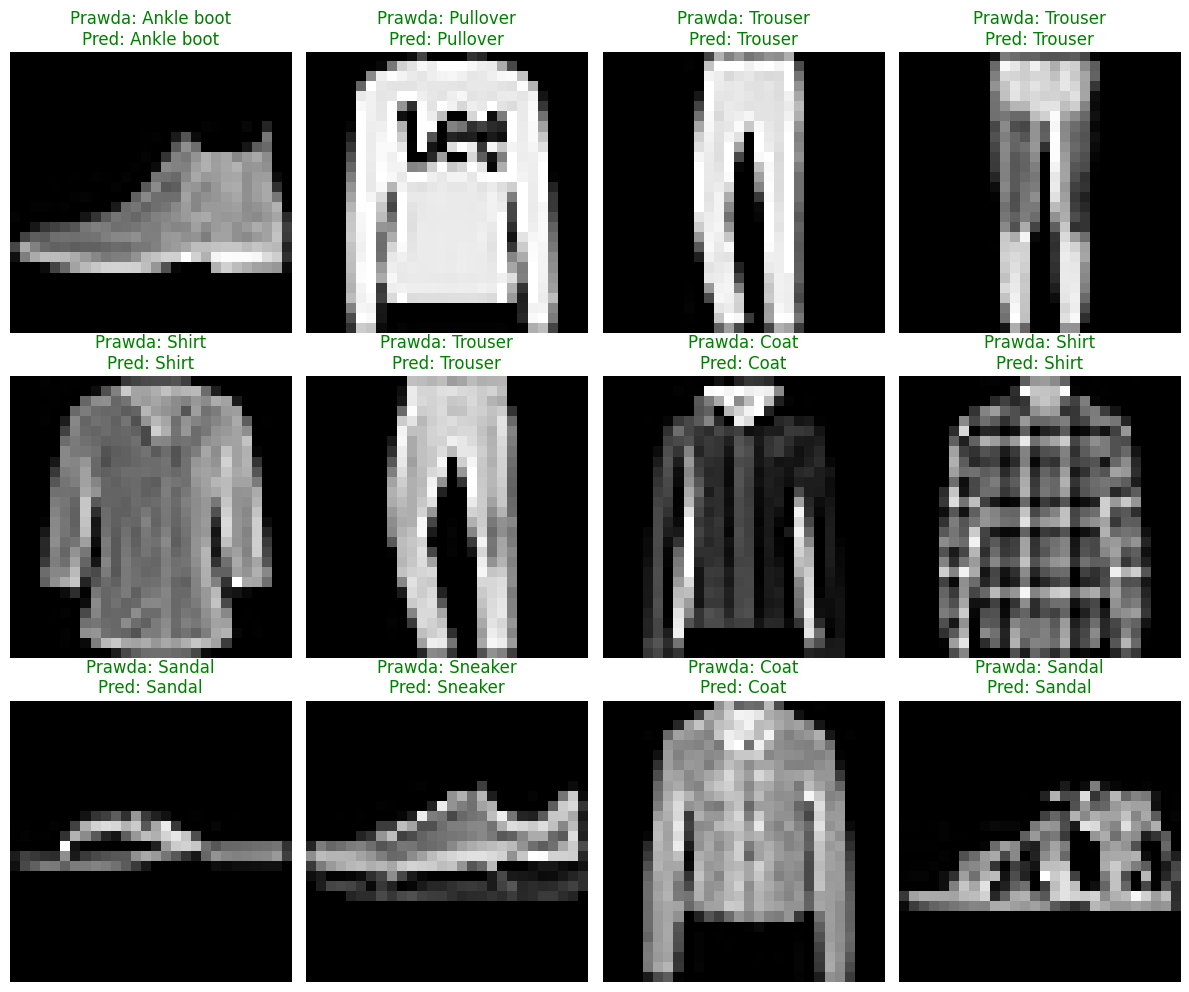

In [11]:
fig, axes = plt.subplots(3, 4, figsize=(12, 10))
for i, ax in enumerate(axes.flatten()):
    img = images[i].cpu().numpy().squeeze()
    ax.imshow(img, cmap='gray')
    true_label = classes[labels[i]]
    pred_label = classes[preds[i]]
    color = 'green' if true_label == pred_label else 'red'
    ax.set_title(f"Prawda: {true_label}\nPred: {pred_label}", color=color)
    ax.axis('off')
plt.tight_layout()
plt.show()